# 10. Fault timing and magnitude

By default every fault acts in IndPenSim's fixed windows: the aeration fault always starts at 20 h, the coolant
fault always at 70 h. A classifier trained on such batches can recognise a fault from the clock instead of from the
process. This notebook shows the fault options, an addition to IndPenSim: the onset, duration and magnitude of each
fault window, fixed or random, and its shape (a step or a ramp). See [Faults](../faults.md#fault-timing-and-magnitude)
for the full reference.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

from penicillium import Fault, FaultSpec, RamanMode, SimulationConfig, Simulator, scenarios
from penicillium.faults import Normal, Uniform, draw_windows

OFF = {"raman_mode": RamanMode.OFF}  # no spectra: faster

## IndPenSim's windows are the default, and a preset

`FaultSpec.indpensim(fault)` returns IndPenSim's windows as specs. They give the same batch as the plain fault
code, bit for bit:

In [2]:
for spec in FaultSpec.indpensim("aeration"):
    print(spec.onset_h, "h for", spec.duration_h, "h, Fg forced to", spec.magnitude)

plain = Simulator(config=SimulationConfig(fault=Fault.AERATION, batch_length_h=120.0, **OFF)).run(seed=1)
preset = Simulator(
    config=SimulationConfig(fault_specs=FaultSpec.indpensim("aeration"), batch_length_h=120.0, **OFF)
).run(seed=1)
print("identical channels:", all(np.array_equal(plain[c], preset[c], equal_nan=True) for c in plain.data))

20.0 h for 4.0 h, Fg forced to 20.0
100.0 h for 10.0 h, Fg forced to 20.0


identical channels: True


## One line: random timing

`randomise=True` draws the onset and the duration from the batch seed; the magnitude stays IndPenSim's. Each batch
records the window it drew in `metadata["fault_windows"]`, and `Fault_ref` marks exactly those samples.

seed 1: 90.4 h to 95.0 h, Fg = 20.0


seed 2: 32.4 h to 36.6 h, Fg = 20.0


seed 3: 44.6 h to 49.2 h, Fg = 20.0


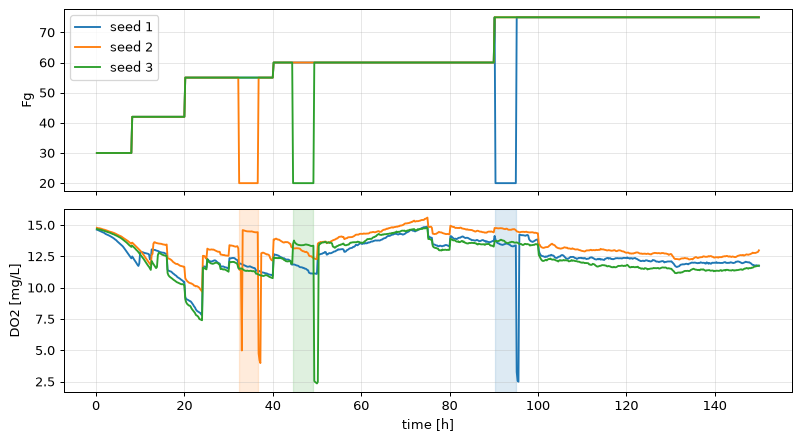

In [3]:
cfg = SimulationConfig(fault_specs=FaultSpec("aeration", randomise=True), batch_length_h=150.0, **OFF)
fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
for seed in (1, 2, 3):
    r = Simulator(config=cfg).run(seed=seed)
    (w,) = r.metadata["fault_windows"]
    print(f"seed {seed}: {w['onset_h']:.1f} h to {w['end_h']:.1f} h, Fg = {w['magnitude']}")
    (line,) = axes[0].plot(r.time, r["Fg"], label=f"seed {seed}")
    axes[1].plot(r.time, r["DO2"], color=line.get_color())
    axes[1].axvspan(w["onset_h"], w["end_h"], color=line.get_color(), alpha=0.15)
axes[0].set_ylabel("Fg")
axes[1].set_ylabel("DO2 [mg/L]")
axes[1].set_xlabel("time [h]")
axes[0].legend()
plt.tight_layout()

## Fully custom: fixed values or distributions

Each of `onset_h`, `duration_h` and `magnitude` takes a number or a distribution (`Uniform`, `Normal`, `Choice`).
`effect` says how the magnitude acts: `"set"` forces the input to the magnitude (IndPenSim's faults), `"scale"`
removes a fraction of it, `"offset"` adds to it. Here the sugar feed loses 60 % of its flow for about 8 h, at a
random time between 30 and 120 h:

In [4]:
leak = FaultSpec(
    "substrate_feed", onset_h=Uniform(30, 120), duration_h=Normal(8, 2, low=1), magnitude=0.6, effect="scale"
)
cfg = SimulationConfig(fault_specs=leak, batch_length_h=150.0, **OFF)
r = Simulator(config=cfg).run(seed=4)
ref = Simulator(config=SimulationConfig(batch_length_h=150.0, **OFF)).run(seed=4)
pd.DataFrame(r.metadata["fault_windows"])

,fault,fault_name,target,effect,shape,hold,onset_h,end_h,magnitude
0,3,SUBSTRATE_FEED,Fs,scale,step,False,50.0,55.8,0.6


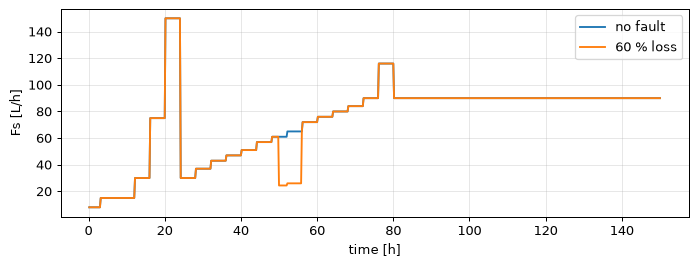

In [5]:
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(ref.time, ref["Fs"], label="no fault")
ax.plot(r.time, r["Fs"], label="60 % loss")
ax.set(xlabel="time [h]", ylabel="Fs [L/h]")
ax.legend();

## Shapes: steps, ramps and your own ramp

A `"ramp"` rises linearly from 0 at the onset to the magnitude at the end of the window, then drops back to 0. A
function `f(tau)`, where `tau` is the fraction of the window elapsed, gives a ramp of any form; `hold=True` keeps the
peak after the window, as IndPenSim's sensor drift does. Below, the offset of a temperature reading for four
shapes (define your function at module level: campaigns with `n_jobs > 1` need to pickle it):

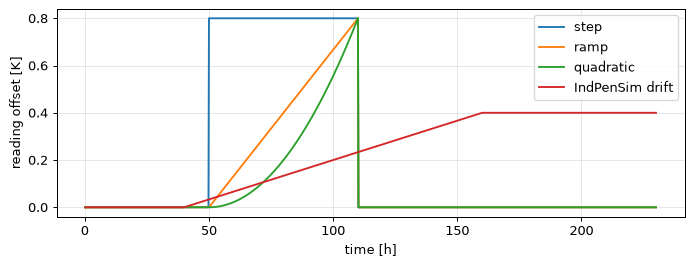

In [6]:
def quadratic(tau: float) -> float:
    return tau**2


shapes = {
    "step": FaultSpec("temperature_sensor", onset_h=50, duration_h=60, magnitude=0.8, shape="step"),
    "ramp": FaultSpec("temperature_sensor", onset_h=50, duration_h=60, magnitude=0.8, shape="ramp"),
    "quadratic": FaultSpec("temperature_sensor", onset_h=50, duration_h=60, magnitude=0.8, shape=quadratic),
    "IndPenSim drift": FaultSpec.indpensim("temperature_sensor")[0],
}
k = np.arange(1, 1151)
fig, ax = plt.subplots(figsize=(9, 3))
for name, spec in shapes.items():
    (w,) = draw_windows([spec], seed=0, n_steps=len(k))
    ax.plot(k * 0.2, [w.amount(i) if w.acts(i) else 0.0 for i in k], label=name)
ax.set(xlabel="time [h]", ylabel="reading offset [K]")
ax.legend();

The controller believes the low reading, so the true broth temperature rises by the offset while the fault acts:

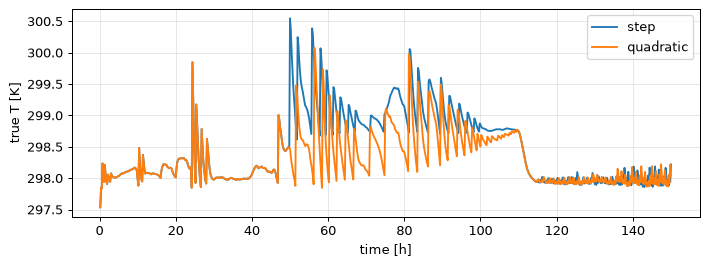

In [7]:
fig, ax = plt.subplots(figsize=(9, 3))
for name in ("step", "quadratic"):
    r = Simulator(config=SimulationConfig(fault_specs=shapes[name], batch_length_h=150.0, **OFF)).run(seed=1)
    ax.plot(r.time, r["T"], label=name)
ax.set(xlabel="time [h]", ylabel="true T [K]")
ax.legend();

## A campaign with random timing

`fault_campaign(..., randomise=True)` gives every faulty batch its own window. `camp.fault_windows` lists them, and
`batches` gains `fault_end_h`. With IndPenSim's windows every batch of a fault type starts at the same time; with
random timing the onsets overlap across fault types, so the clock no longer tells them apart:

In [8]:
cfg = SimulationConfig(batch_length_h=230.0, **OFF)
faults = (Fault.AERATION, Fault.PRESSURE, Fault.SUBSTRATE_FEED, Fault.COOLANT_FLOW)
fixed = scenarios.fault_campaign(n_normal=0, n_per_fault=6, faults=faults, seed=1, config=cfg)
random = scenarios.fault_campaign(n_normal=0, n_per_fault=6, faults=faults, seed=1, config=cfg, randomise=True)
random.fault_windows.head()

,batch_id,fault,fault_name,target,effect,shape,hold,onset_h,end_h,magnitude
0,1,1,AERATION,Fg,set,step,False,149.4,156.4,20.0
1,2,1,AERATION,Fg,set,step,False,129.8,137.8,20.0
2,3,1,AERATION,Fg,set,step,False,149.2,158.0,20.0
3,4,1,AERATION,Fg,set,step,False,40.8,50.2,20.0
4,5,1,AERATION,Fg,set,step,False,151.8,157.6,20.0


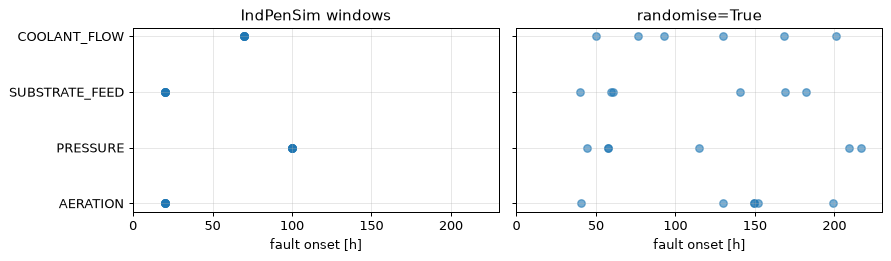

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, camp, title in ((axes[0], fixed, "IndPenSim windows"), (axes[1], random, "randomise=True")):
    b = camp.batches
    ax.scatter(b.fault_onset_h, b.fault_name, alpha=0.6)
    ax.set(title=title, xlabel="fault onset [h]", xlim=(0, 230))
plt.tight_layout()

## Reproducible, and independent of the other random inputs

The windows come from the batch seed, each value from its own random stream. The same seed gives the same window in
every run and process, and switching the options on does not change the batch's initial state, parameters,
disturbances, PRBS steps or noise:

In [10]:
spec = FaultSpec("pressure", randomise=True)
print(draw_windows([spec], seed=7, n_steps=1150) == draw_windows([spec], seed=7, n_steps=1150))
print(Simulator.initial_conditions(seed=7) == Simulator.initial_conditions(seed=7))  # independent of the faults
a = Simulator(config=SimulationConfig(fault_specs=spec, batch_length_h=230.0, **OFF)).run(seed=7)
b = Simulator(config=SimulationConfig(batch_length_h=230.0, **OFF)).run(seed=7)
onset = int(np.flatnonzero(a["Fault_ref"])[0])
print(
    "identical before the fault:",
    all(np.array_equal(a[c][:onset], b[c][:onset], equal_nan=True) for c in a.data if c != "Fault_ref"),
)

True
True


identical before the fault: True


## Next

- [Faults](../faults.md#fault-timing-and-magnitude): every option, what the magnitude means for each fault, labels.
- [Tutorial 5](05_campaigns_and_fault_detection.ipynb): build a monitor; try it on a campaign with `randomise=True`.